# General

In [1]:
import os
import json
import hashlib
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input, decode_predictions

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [3]:
records = json.loads(Path('images/manifest.json').read_text())
labels = pd.DataFrame(records)[['file', 'class', 'synset', 'index']]
img_files = [Path('images') / record['file'] for record in records]
display(labels)

,file,class,synset,index
0,airliner.jpg,airliner,n02690373,404
1,container_ship.jpg,container_ship,n03095699,510
2,Siamese_cat.jpg,Siamese_cat,n02123597,284
3,golden_retriever.jpg,golden_retriever,n02099601,207
4,zebra.jpg,zebra,n02391049,340
5,banana.jpg,banana,n07753592,954
6,pineapple.jpg,pineapple,n07753275,953
7,school_bus.jpg,school_bus,n04146614,779
8,fire_engine.jpg,fire_engine,n03345487,555
9,ambulance.jpg,ambulance,n02701002,407


In [4]:
imgs = []
for fname in img_files:
    with Image.open(fname) as img:
        img = ImageOps.exif_transpose(img).convert('RGB')
        imgs.append(img.copy())

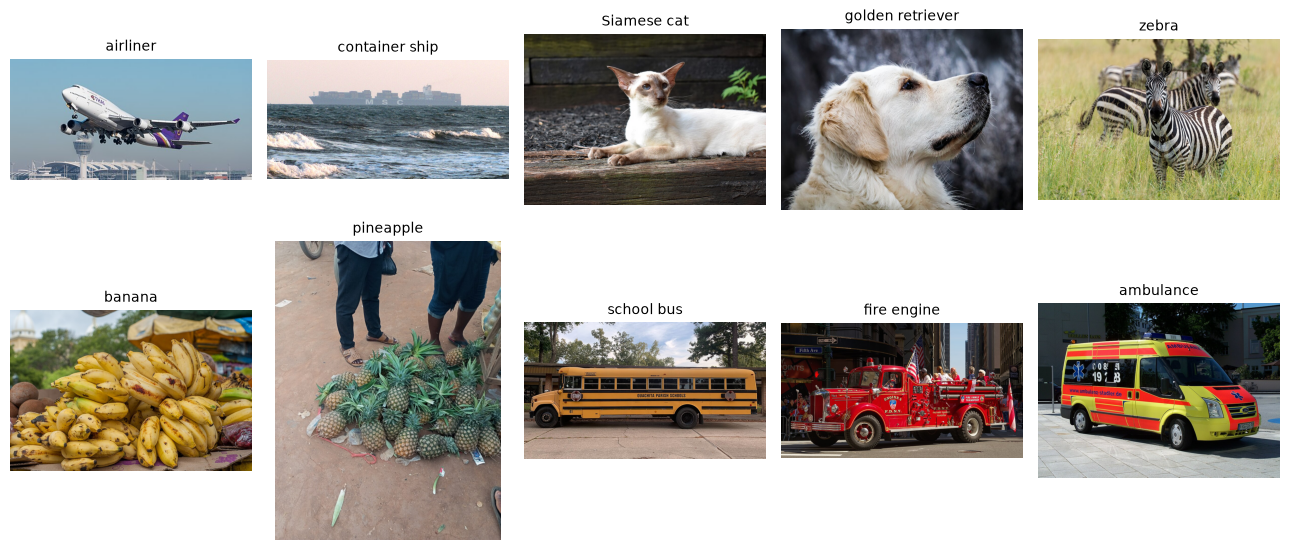

In [5]:
fig, axs = plt.subplots(2, 5, figsize=(13, 6))
for ax, img, label in zip(axs.flat, imgs, labels['class']):
    ax.imshow(img)
    ax.set_title(label.replace('_', ' '), fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Model

In [6]:
model_name = 'mobilenet_v2'
image_size = (224, 224)
model = MobileNetV2(weights='imagenet', include_top=True)
model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 3,538,984 (13.50 MB)

 Trainable params: 3,504,872 (13.37 MB)

 Non-trainable params: 34,112 (133.25 KB)

# Preprocessing

In [7]:
resized_imgs = []
for img in imgs:
    img = img.resize(image_size, Image.Resampling.BILINEAR)
    resized_imgs.append(np.asarray(img, dtype='float32'))
resized_imgs = np.array(resized_imgs)

In [8]:
x = preprocess_input(resized_imgs.copy())
print('Input shape:', x.shape)
print('Pixel range:', x.min(), x.max())

Input shape: (10, 224, 224, 3)
Pixel range: -1.0 1.0


# Recognition

In [9]:
probabilities = model.predict(x, batch_size=2, verbose=0)
decoded = decode_predictions(probabilities, top=5)

In [10]:
rows = []
for record, predictions in zip(records, decoded):
    synset, label, confidence = predictions[0]
    top_synsets = [prediction[0] for prediction in predictions]
    top3 = [f'{label} ({score:.1%})' for _, label, score in predictions[:3]]
    rows.append({
        'image': record['file'],
        'class': record['class'],
        'expected_synset': record['synset'],
        'prediction': label,
        'predicted_synset': synset,
        'confidence': float(confidence),
        'top1_correct': synset == record['synset'],
        'top5_correct': record['synset'] in top_synsets,
        'top3': ', '.join(top3)
    })
results = pd.DataFrame(rows)
display(results[['image', 'class', 'prediction', 'confidence', 'top1_correct', 'top5_correct']])

,image,class,prediction,confidence,top1_correct,top5_correct
0,airliner.jpg,airliner,airliner,0.795344,True,True
1,container_ship.jpg,container_ship,grey_whale,0.200985,False,True
2,Siamese_cat.jpg,Siamese_cat,Ibizan_hound,0.494899,False,True
3,golden_retriever.jpg,golden_retriever,golden_retriever,0.447695,True,True
4,zebra.jpg,zebra,zebra,0.876659,True,True
5,banana.jpg,banana,banana,0.889912,True,True
6,pineapple.jpg,pineapple,pineapple,0.523067,True,True
7,school_bus.jpg,school_bus,school_bus,0.964712,True,True
8,fire_engine.jpg,fire_engine,fire_engine,0.970409,True,True
9,ambulance.jpg,ambulance,ambulance,0.601528,True,True


In [11]:
top_rows = []
for record, predictions in zip(records, decoded):
    for rank, (synset, label, confidence) in enumerate(predictions, start=1):
        top_rows.append({
            'image': record['file'],
            'rank': rank,
            'synset': synset,
            'prediction': label,
            'confidence': float(confidence),
            'correct': synset == record['synset']
        })
top_results = pd.DataFrame(top_rows)
display(top_results)

,image,rank,synset,prediction,confidence,correct
0,airliner.jpg,1,n02690373,airliner,0.795344,True
1,airliner.jpg,2,n04552348,warplane,0.055719,False
2,airliner.jpg,3,n04592741,wing,0.018426,False
3,airliner.jpg,4,n04266014,space_shuttle,0.016397,False
4,airliner.jpg,5,n02687172,aircraft_carrier,0.011808,False
5,container_ship.jpg,1,n02066245,grey_whale,0.200985,False
6,container_ship.jpg,2,n02687172,aircraft_carrier,0.119626,False
7,container_ship.jpg,3,n04347754,submarine,0.119333,False
8,container_ship.jpg,4,n03095699,container_ship,0.086157,True
9,container_ship.jpg,5,n02894605,breakwater,0.081071,False


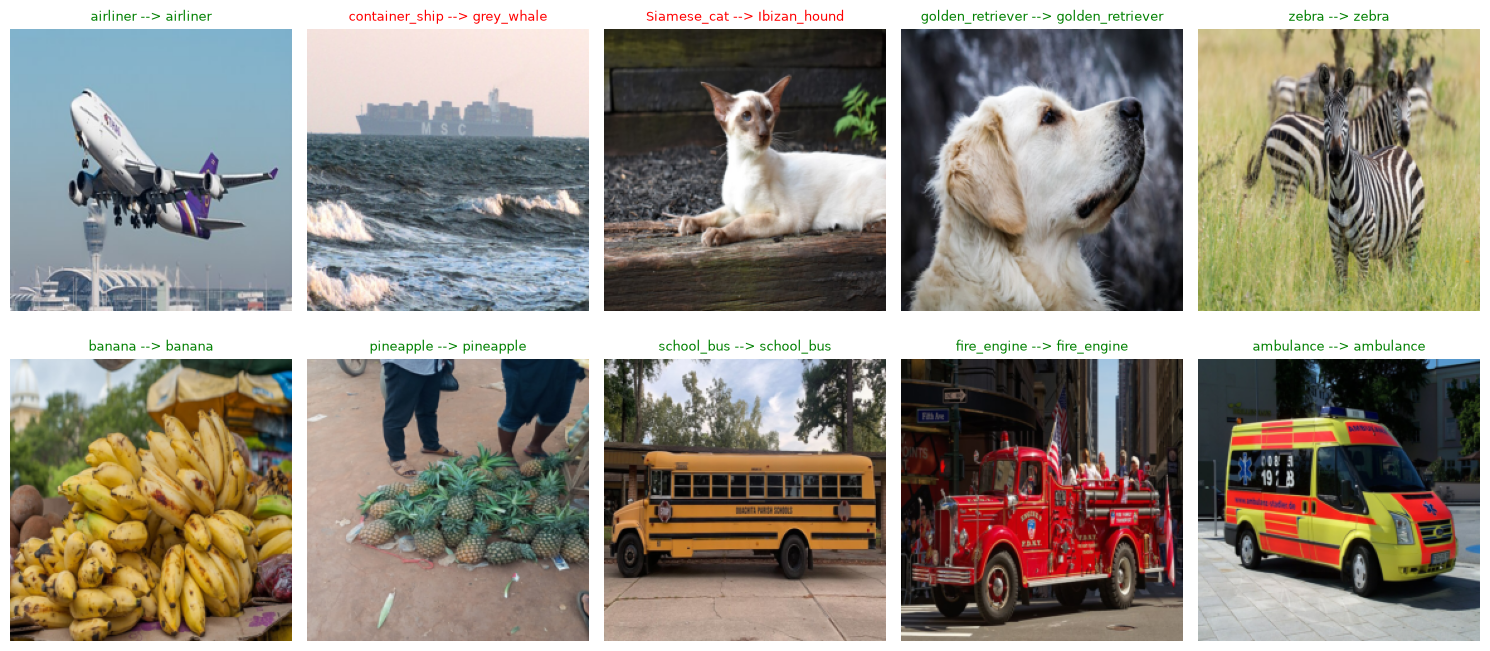

In [12]:
fig, axs = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axs.flat):
    row = results.iloc[i]
    ax.imshow(resized_imgs[i].astype('uint8'))
    ax.set_title(
        f"{row['class']} --> {row['prediction']}",
        fontsize=9,
        color='green' if row['top1_correct'] else 'red'
    )
    ax.axis('off')
plt.tight_layout()
fig.savefig(f'results/{model_name}_predictions.png', dpi=150)
plt.show()

# Results

In [13]:
top1_accuracy = results['top1_correct'].mean()
top5_accuracy = results['top5_correct'].mean()
print(f'Top-1 accuracy: {top1_accuracy:.0%}')
print(f'Top-5 accuracy: {top5_accuracy:.0%}')

Top-1 accuracy: 80%
Top-5 accuracy: 100%


In [14]:
parameters = model.count_params()
weight_bytes = 0
for weight in model.weights:
    weight_bytes += int(np.prod(weight.shape)) * np.dtype(weight.dtype).itemsize
weights_mib = weight_bytes / 1024 ** 2
print(f'Parameters: {parameters:,}')
print(f'Weight memory: {weights_mib:.2f} MiB')

Parameters: 3,538,984
Weight memory: 13.50 MiB


In [15]:
timings = []
for _ in range(5):
    start = perf_counter()
    model.predict(x, batch_size=2, verbose=0)
    elapsed = perf_counter() - start
    timings.append(elapsed * 1000 / len(x))
inference_ms = float(np.median(timings))
print(f'Inference: {inference_ms:.2f} ms/image')

Inference: 8.71 ms/image


In [16]:
manifest_bytes = Path('images/manifest.json').read_bytes()
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
metrics = {
    'model': model_name,
    'images': len(results),
    'top1_accuracy': float(top1_accuracy),
    'top5_accuracy': float(top5_accuracy),
    'parameters': parameters,
    'weights_mib': weights_mib,
    'input_size': list(image_size),
    'batch_size': 2,
    'inference_ms_per_image': inference_ms,
    'timings_ms_per_image': timings,
    'manifest_sha256': manifest_sha256,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'device': 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'
}

# Saving

In [17]:
results.to_csv(f'results/{model_name}_predictions.csv', index=False)
top_results.to_csv(f'results/{model_name}_top5.csv', index=False)
np.savez_compressed(
    f'results/{model_name}_probabilities.npz',
    probabilities=probabilities,
    images=np.array([fname.name for fname in img_files]),
    expected_indices=labels['index'].to_numpy()
)
Path(f'results/{model_name}_metrics.json').write_text(json.dumps(metrics, indent=4));

# Comparison

In [18]:
model_names = ['vgg16', 'resnet50', 'inception_v3', 'mobilenet_v2']
all_metrics = []
for name in model_names:
    row = json.loads(Path(f'results/{name}_metrics.json').read_text())
    assert row['manifest_sha256'] == manifest_sha256
    assert row['images'] == len(records)
    all_metrics.append(row)

columns = [
    'model', 'top1_accuracy', 'top5_accuracy', 'parameters', 'weights_mib',
    'input_size', 'batch_size', 'inference_ms_per_image', 'device'
]
comparison = pd.DataFrame(all_metrics)[columns]
comparison.to_csv('results/comparison.csv', index=False)
display(comparison)

,model,top1_accuracy,top5_accuracy,parameters,weights_mib,input_size,batch_size,inference_ms_per_image,device
0,vgg16,0.8,0.9,138357544,527.792145,"[224, 224]",2,17.662830,GPU
1,resnet50,0.8,1.0,25636712,97.796295,"[224, 224]",2,13.499975,GPU
2,inception_v3,1.0,1.0,23851784,90.987335,"[299, 299]",2,14.753935,GPU
3,mobilenet_v2,0.8,1.0,3538984,13.500153,"[224, 224]",2,8.707092,GPU


In [19]:
tables = []
for name in model_names:
    table = pd.read_csv(f'results/{name}_predictions.csv')
    table['model'] = name
    tables.append(table)
all_results = pd.concat(tables, ignore_index=True)
all_results.to_csv('results/all_predictions.csv', index=False)
display(all_results.pivot(index='image', columns='model', values='prediction'))

model,inception_v3,mobilenet_v2,resnet50,vgg16
image,,,,
Siamese_cat.jpg,Siamese_cat,Ibizan_hound,Chihuahua,Siamese_cat
airliner.jpg,airliner,airliner,airliner,warplane
ambulance.jpg,ambulance,ambulance,ambulance,ambulance
banana.jpg,banana,banana,banana,banana
container_ship.jpg,container_ship,grey_whale,submarine,promontory
fire_engine.jpg,fire_engine,fire_engine,fire_engine,fire_engine
golden_retriever.jpg,golden_retriever,golden_retriever,golden_retriever,golden_retriever
pineapple.jpg,pineapple,pineapple,pineapple,pineapple
school_bus.jpg,school_bus,school_bus,school_bus,school_bus


In [20]:
correct = all_results.pivot(index='image', columns='model', values='top1_correct')
correct.to_csv('results/correct_by_image.csv')
display(correct)

model,inception_v3,mobilenet_v2,resnet50,vgg16
image,,,,
Siamese_cat.jpg,True,False,False,True
airliner.jpg,True,True,True,False
ambulance.jpg,True,True,True,True
banana.jpg,True,True,True,True
container_ship.jpg,True,False,False,False
fire_engine.jpg,True,True,True,True
golden_retriever.jpg,True,True,True,True
pineapple.jpg,True,True,True,True
school_bus.jpg,True,True,True,True


In [21]:
best_accuracy = comparison['top1_accuracy'].max()
winners = comparison.loc[comparison['top1_accuracy'] == best_accuracy, 'model']
print('Best top-1 accuracy:', ', '.join(winners), f'({best_accuracy:.0%})')

Best top-1 accuracy: inception_v3 (100%)


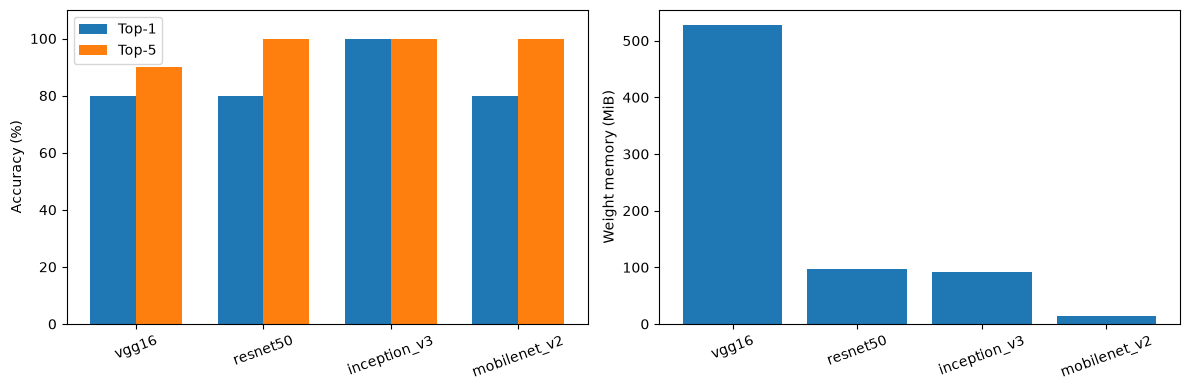

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(comparison))
axs[0].bar(positions - 0.18, comparison['top1_accuracy'] * 100, width=0.36, label='Top-1')
axs[0].bar(positions + 0.18, comparison['top5_accuracy'] * 100, width=0.36, label='Top-5')
axs[0].set_ylim(0, 110)
axs[0].set_ylabel('Accuracy (%)')
axs[0].set_xticks(positions, comparison['model'], rotation=20)
axs[0].legend()
axs[1].bar(comparison['model'], comparison['weights_mib'])
axs[1].set_ylabel('Weight memory (MiB)')
axs[1].tick_params(axis='x', labelrotation=20)
plt.tight_layout()
fig.savefig('results/comparison.png', dpi=150)
plt.show()

# Summary

**MobileNetV2** використано з вагами ImageNet, без додаткового навчання. Зображення зменшено до 224x224, підготовка даних - масштабування до [-1, 1]. Точність top-1 - **80%**, top-5 - **100%**. Помилки top-1: `container_ship.jpg` --> `grey_whale`; `Siamese_cat.jpg` --> `Ibizan_hound`.

Модель має **3,538,984 параметрів**. Медіанний час після прогріву - 8.71 мс на зображення при пакеті 2 на GPU. Час включає виклик predict.

| Model | Top-1 | Top-5 | Parameters | Weight memory (MiB) | Inference (ms/image) |
|---|---:|---:|---:|---:|---:|
| vgg16 | 80% | 90% | 138,357,544 | 527.79 | 17.66 |
| resnet50 | 80% | 100% | 25,636,712 | 97.80 | 13.50 |
| inception_v3 | 100% | 100% | 23,851,784 | 90.99 | 14.75 |
| mobilenet_v2 | 80% | 100% | 3,538,984 | 13.50 | 8.71 |

На тих самих десяти фотографіях найвищу точність top-1 отримано для **inception_v3**: **100%**. Найменший обсяг ваг має MobileNetV2 - 13.50 MiB.